# 02 · Модели и эксперименты

Результаты экспериментов 01–05. Числа берутся из файлов `experiments/*/results.json`,
которые лежат в репозитории, поэтому ноутбук работает и без полных данных. Графики,
которым нужны прогнозы на тестовой выборке, рисуются, только если есть рабочая папка с
обученными моделями.

**Как читать метрики:**

- **медианная ошибка** — на сколько процентов прогноз отличается от реальной цены в
  типичном случае (у половины продаж меньше, у половины больше);
- **средняя ошибка, $** — на сколько долларов модель промахивается в среднем;
- **ошибка p90** — у 9 прогнозов из 10 ошибка не больше этого значения;
- **цена в интервале** — как часто реальная цена попадает в 70%-вилку модели (в идеале 70%).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from skinprice import paths
from skinprice.research.labels import russian, value
from skinprice.research.plots import MODEL_COLORS, NEUTRAL, SERIES, apply_style, bar_labels

apply_style()


def results(slug: str) -> dict:
    return json.loads((paths.EXPERIMENTS_DIR / slug / "results.json").read_text(encoding="utf-8"))


def summary(slug: str) -> pd.DataFrame:
    rows = []
    for label, r in results(slug).items():
        if "metrics" in r:
            rows.append({"variant": label, "model": r.get("model"), "size_mb": r.get("size_mb"),
                         "fit_minutes": r.get("fit_minutes"), **r["metrics"]["test"]})
    return pd.DataFrame(rows).set_index("variant")

## Сравнение моделей (эксперимент 02)

У всех моделей одинаковые признаки и одинаковое разбиение по времени. Тест — самые новые
20% продаж: 164 тысячи продаж за 2–10 августа 2026 года.

- `csfloat_reference` и `recent_median` — простые ориентиры без обучения: оценка CSFloat
  и медиана последних 20 продаж такого же предмета.
- `premium_catboost`, `target_encoded_hgb` и `quantile_mlp` — обучаемые модели: два
  градиентных бустинга и нейросеть.
- `ensemble_*` — среднее нескольких моделей.

In [2]:
comparison = summary("02_model_comparison")
cols = ["model", "median_ape", "mean_ape", "p90_ape", "mae_usd", "within_10pct", "interval_coverage", "size_mb", "fit_minutes"]
russian(comparison[cols].round(2))

,модель,"медианная ошибка, %","средняя ошибка, %","ошибка p90, %","средняя ошибка, $","ошибка ≤10%, доля %","цена в интервале, %","размер, МБ","обучение, мин"
вариант,,,,,,,,,
csfloat_reference,csfloat_reference,5.99,15.00,40.53,2.37,62.18,70.08,0.00,0.0
recent_median,recent_median,7.91,18.17,44.44,2.92,55.64,69.55,0.00,0.0
target_encoded_hgb,target_encoded_hgb,4.65,11.02,26.12,1.37,69.42,71.08,7.77,5.1
quantile_mlp,quantile_mlp,4.67,11.47,25.20,1.42,70.37,68.99,11.72,43.9
premium_catboost,premium_catboost,4.96,11.39,26.75,1.38,68.70,65.86,6.23,21.8
ensemble_all3,ансамбль из 3 моделей,4.60,10.59,24.65,1.27,70.35,71.71,NaN,NaN
ensemble_catboost_mlp,ансамбль из 2 моделей,4.68,10.72,24.51,1.28,70.37,70.52,NaN,NaN


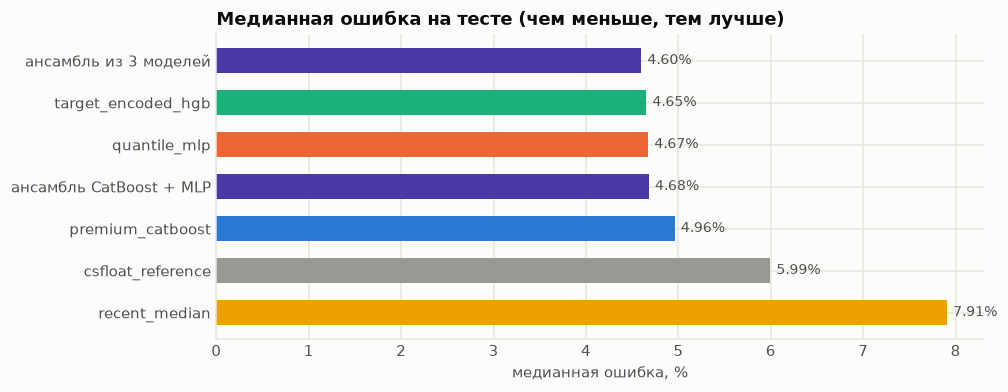

In [3]:
order = comparison["median_ape"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [MODEL_COLORS.get(v, SERIES[6]) for v in order.index]
ENSEMBLE_NAMES = {"ensemble_all3": "ансамбль из 3 моделей", "ensemble_catboost_mlp": "ансамбль CatBoost + MLP"}
bars = ax.barh([ENSEMBLE_NAMES.get(v, v) for v in order.index], order.values, height=0.6, color=colors)
bar_labels(ax, bars, "{:.2f}%")
ax.set_title("Медианная ошибка на тесте (чем меньше, тем лучше)")
ax.set_xlabel("медианная ошибка, %")
plt.show()

Точность сильно зависит от цены. Дешёвые лоты стоят целое число центов, поэтому промах на
один цент у предмета за $0,10 — это уже 10% ошибки. На дорогих крафтах оценка CSFloat
ошибается сильнее всего, потому что не видит наклеек, а модели исправляют это лучше всего.

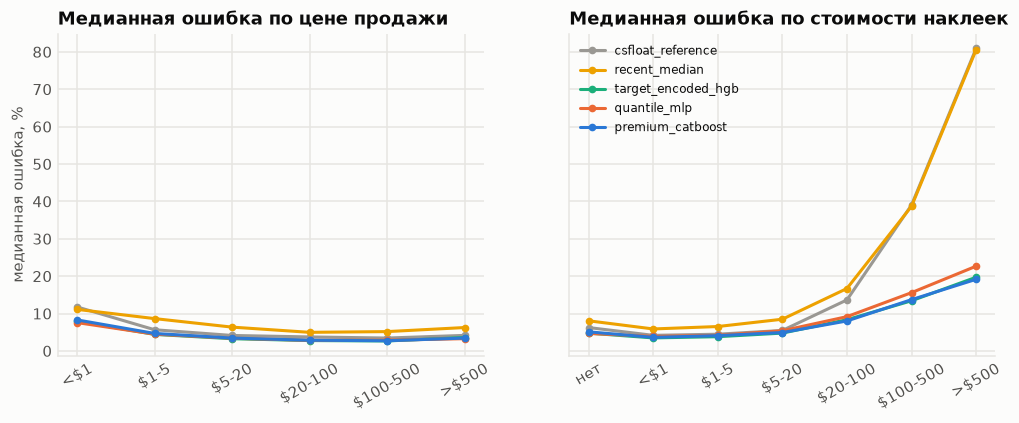

In [4]:
segments_path = paths.workspace().runs_dir / "02_model_comparison"
if segments_path.exists():
    from skinprice.evaluation.metrics import segment_table
    from skinprice.features.build import load_features

    features = load_features(columns=["listing_id", "split", "price_cents", "sticker_count", "keychain_count",
                                      "log_sticker_sum_ref_price", "blue_playside", "fade_percentage"])
    test = features[features["split"] == "test"]
    models = ["csfloat_reference", "recent_median", "target_encoded_hgb", "quantile_mlp", "premium_catboost"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, by, title in ((axes[0], "price_band", "по цене продажи"), (axes[1], "sticker_value", "по стоимости наклеек")):
        for name in models:
            pred = pd.read_parquet(segments_path / name / "test_predictions.parquet").set_index("listing_id").reindex(test["listing_id"])
            table = segment_table(test, pred["pred_cents"].to_numpy(), by)
            ax.plot([value(str(v)) for v in table[by]], table["median_ape"], marker="o", markersize=4,
                    color=MODEL_COLORS[name], label=name)
        ax.set_title(f"Медианная ошибка {title}")
        ax.tick_params(axis="x", rotation=30)
    axes[0].set_ylabel("медианная ошибка, %")
    axes[1].legend(loc="upper left", fontsize=8)
    plt.show()

## Цена или наценка? (эксперимент 01)

Три модели CatBoost с одинаковыми настройками:

- `price_no_reference` предсказывает цену и не знает оценки CSFloat;
- `price_with_reference` предсказывает цену и видит оценку CSFloat как обычный признак;
- `premium` предсказывает наценку к оценке CSFloat.

Знание оценки CSFloat снижает ошибку втрое. Если вдобавок предсказывать отклонение от
неё, долларовая ошибка падает ещё на 28%. Колонка «медиана прогноз/факт» показывает
систематический сдвиг: 1,00 — сдвига нет, меньше 1 — модель занижает цену.

In [5]:
target = summary("01_premium_target")
russian(target[["median_ape", "mean_ape", "p90_ape", "mae_usd", "median_ratio"]].round(3))

,"медианная ошибка, %","средняя ошибка, %","ошибка p90, %","средняя ошибка, $",медиана прогноз/факт
вариант,,,,,
price_no_reference,14.729,23.607,51.199,5.256,1.013
price_with_reference,5.455,11.758,27.346,1.930,1.003
premium,4.960,11.390,26.749,1.379,0.997


## Сжатие модели (эксперимент 03): размер против точности

Исходная модель CatBoost весила 8 ГБ. Почти весь объём занимали таблицы статистики по
*сочетаниям* категорий (например, «скин + номер паттерна»), и для каждого встреченного
сочетания хранилась своя строка. Если запретить сочетания и убрать почти уникальный
признак «скин + паттерн», модель становится в тысячу раз меньше, а точность остаётся
прежней.

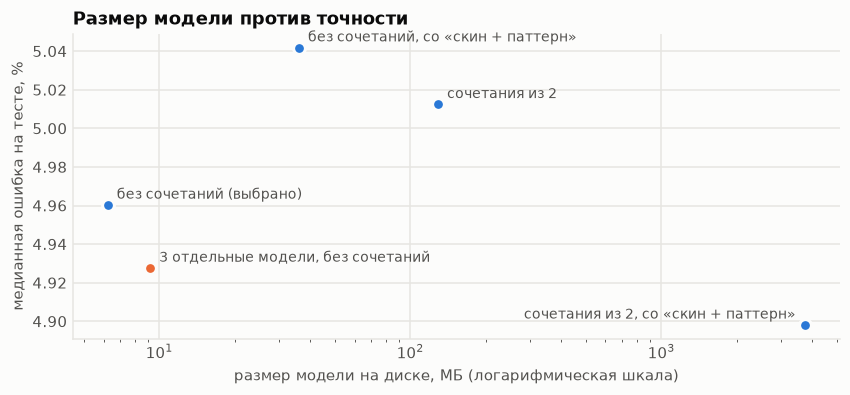

,"медианная ошибка, %","ошибка p90, %","средняя ошибка, $","цена в интервале, %","размер, МБ","обучение, мин"
вариант,,,,,,
multi_ctr1,5.04,26.50,1.44,65.32,36.00,21.8
multi_ctr2,4.90,25.88,1.36,67.98,3745.03,52.0
multi_ctr2_no_seed_key,5.01,26.14,1.38,66.24,128.99,41.3
multi_ctr1_no_seed_key,4.96,26.75,1.38,65.86,6.23,21.1
separate_ctr1_no_seed_key,4.93,26.18,1.40,69.48,9.19,27.3


In [6]:
COMPRESSION_NAMES = {
    "multi_ctr1": "без сочетаний, со «скин + паттерн»",
    "multi_ctr2": "сочетания из 2, со «скин + паттерн»",
    "multi_ctr2_no_seed_key": "сочетания из 2",
    "multi_ctr1_no_seed_key": "без сочетаний (выбрано)",
    "separate_ctr1_no_seed_key": "3 отдельные модели, без сочетаний",
}
compression = summary("03_model_compression")
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (label, row) in enumerate(compression.iterrows()):
    color = SERIES[0] if label.startswith("multi") else SERIES[1]
    ax.scatter(row["size_mb"], row["median_ape"], s=60, color=color, edgecolor="#fcfcfb", linewidth=2, zorder=3)
    right = row["size_mb"] > 1000  # the rightmost point is labelled on its left
    ax.annotate(COMPRESSION_NAMES.get(label, label), (row["size_mb"], row["median_ape"]), xytext=(-6 if right else 6, 4),
                textcoords="offset points", ha="right" if right else "left", fontsize=9, color="#52514e")
ax.set_xscale("log")
ax.set_xlabel("размер модели на диске, МБ (логарифмическая шкала)")
ax.set_ylabel("медианная ошибка на тесте, %")
ax.set_title("Размер модели против точности")
plt.show()
russian(compression[["median_ape", "p90_ape", "mae_usd", "interval_coverage", "size_mb", "fit_minutes"]].round(2))

## Какие признаки важны (эксперимент 04)

Из модели по очереди убирают одну группу признаков (−) или добавляют новую (+) и
смотрят, как меняется медианная ошибка. Если ошибка выросла (столбик вправо), группа
полезна. Модель CatBoost обучена на 200 тысячах самых свежих строк.

Серая полоса — шум: так сильно меняется результат одной и той же модели, если обучить
её с другим случайным зерном. Эффекты внутри полосы ничего не значат.

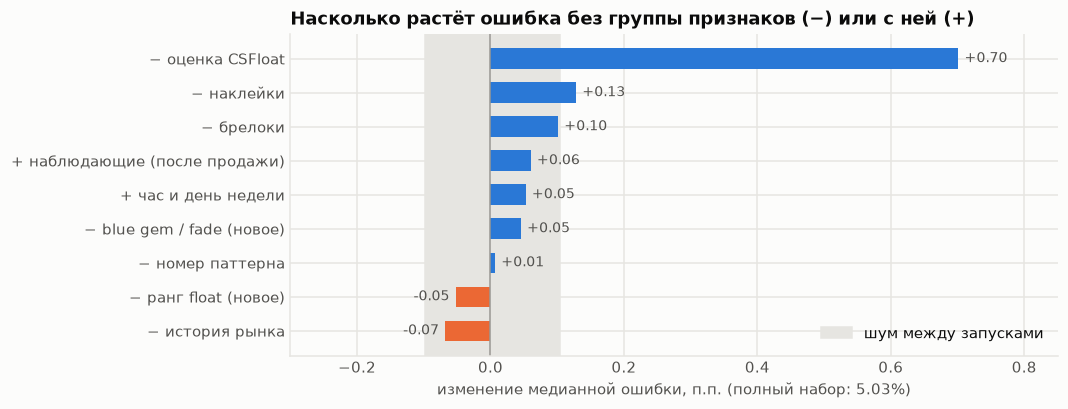

In [7]:
ABLATION_NAMES = {
    "minus_reference": "− оценка CSFloat",
    "minus_stickers": "− наклейки",
    "minus_keychains": "− брелоки",
    "minus_pattern_seed": "− номер паттерна",
    "minus_float_rank": "− ранг float (новое)",
    "minus_pattern_extras": "− blue gem / fade (новое)",
    "minus_market_history": "− история рынка",
    "plus_lot_behavior": "+ наблюдающие (после продажи)",
    "plus_calendar": "+ час и день недели",
}
ablation = summary("04_feature_ablation")
seeds = ablation.loc[["all_default", "all_default_seed7", "all_default_seed123"], "median_ape"]
base = ablation.loc["all_default", "median_ape"]
subsample = ablation[ablation.index.str.startswith(("minus_", "plus_"))]
delta = (subsample["median_ape"] - base).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axvspan(seeds.min() - base, seeds.max() - base, color="#e6e5e1", zorder=0, label="шум между запусками")
bars = ax.barh([ABLATION_NAMES.get(i, i) for i in delta.index], delta.values, height=0.6,
               color=[SERIES[0] if v >= 0 else SERIES[1] for v in delta.values])
bar_labels(ax, bars, "{:+.2f}")
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.set_xlim(-0.3, 0.85)
ax.set_title("Насколько растёт ошибка без группы признаков (−) или с ней (+)")
ax.set_xlabel(f"изменение медианной ошибки, п.п. (полный набор: {base:.2f}%)")
ax.legend(loc="lower right")
plt.show()

Удаление истории рынка на подвыборке не навредило CatBoost. Это перепроверено на полных
данных для двух моделей: модели scikit-learn история рынка помогает (4,65% против 4,88%),
CatBoost нет.

In [8]:
full = ablation.loc[[i for i in ablation.index if i.startswith("full_")], ["model", "median_ape", "mae_usd"]]
full.index = ["с историей рынка" if "minus" not in i else "без истории рынка" for i in full.index]
russian(full.round(3)).rename_axis("вариант")

,модель,"медианная ошибка, %","средняя ошибка, $"
вариант,,,
с историей рынка,premium_catboost,4.960,1.379
без истории рынка,premium_catboost,4.898,1.330
с историей рынка,target_encoded_hgb,4.652,1.368
без истории рынка,target_encoded_hgb,4.878,1.442


## Цены наклеек «из будущего» (эксперимент 05)

Сборщик данных сохранял цену наклейки на момент скачивания, иногда через недели после
продажи. Могла ли модель из-за этого выглядеть точнее, чем она есть? Сравниваются три
модели: со всеми ценами (`lag_all`), со скрытыми ценами, полученными больше чем через
30 дней (`lag_30`), и больше чем через 3 дня (`lag_3`).

Если скрыть поздние цены, точность не растёт, а при строгом скрытии падает. Значит, тест
не завышен: у 93% тестовых крафтов цены наклеек получены в пределах 3 дней после продажи.

In [9]:
leak = pd.DataFrame(results("05_sticker_reference_leakage")["subsets"]["rows"])
leak["subset"] = leak["subset"].map(value)
leak.pivot(index="subset", columns="variant", values="median_ape").round(2).rename_axis(
    index="подвыборка (медианная ошибка, %)", columns="вариант")

вариант,lag_3,lag_30,lag_all
"подвыборка (медианная ошибка, %)",,,
весь тест,5.02,4.93,4.96
все крафты,4.63,4.40,4.36
крафты с ценой наклейки на 3–30 дн. позже,5.44,5.18,4.99
крафты с ценой наклейки на >30 дн. позже,NaN,NaN,NaN
крафты со свежими ценами наклеек (≤3 дн.),4.57,4.35,4.31


## На что смотрит основная модель

Важность признаков CatBoost: насколько в среднем меняется прогноз, когда меняется
значение признака. Наверху — признаки, которые сильнее всего влияют на оценку.

Главный признак — во сколько раз наклейки дороже самого оружия: именно он решает,
насколько крафт уйдёт выше оценки CSFloat. Дальше идут оценка CSFloat и float.

Важность не то же самое, что незаменимость. Ранг float стоит на втором месте, но
эксперимент 04 показал, что без него модель не хуже: та же информация есть в самом float.

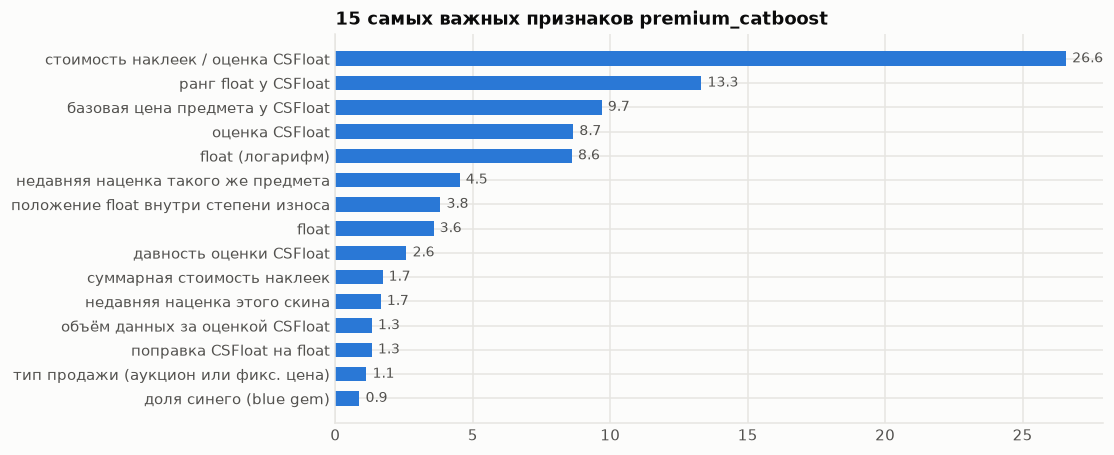

In [10]:
from skinprice import models as model_registry  # noqa: E402

run_dir = paths.workspace().runs_dir / "02_model_comparison" / "premium_catboost"
if run_dir.exists():
    FEATURE_NAMES = {
        "sticker_to_anchor_ratio": "стоимость наклеек / оценка CSFloat",
        "log_high_rank": "ранг float у CSFloat",
        "log_reference_base_price": "базовая цена предмета у CSFloat",
        "log_anchor": "оценка CSFloat",
        "log_float": "float (логарифм)",
        "name_recent_premium": "недавняя наценка такого же предмета",
        "float_band_position": "положение float внутри степени износа",
        "float_value": "float",
        "reference_lag_days": "давность оценки CSFloat",
        "log_sticker_sum_ref_price": "суммарная стоимость наклеек",
        "wt_recent_premium": "недавняя наценка этого скина",
        "log_reference_quantity": "объём данных за оценкой CSFloat",
        "reference_float_factor": "поправка CSFloat на float",
        "sale_type": "тип продажи (аукцион или фикс. цена)",
        "blue_playside": "доля синего (blue gem)",
    }
    importance = model_registry.load(run_dir).feature_importance().head(15)[::-1]
    fig, ax = plt.subplots(figsize=(9, 4.6))
    bars = ax.barh([FEATURE_NAMES.get(n, n) for n in importance.index], importance.values, height=0.6, color=SERIES[0])
    bar_labels(ax, bars, "{:.1f}")
    ax.set_title("15 самых важных признаков premium_catboost")
    plt.show()